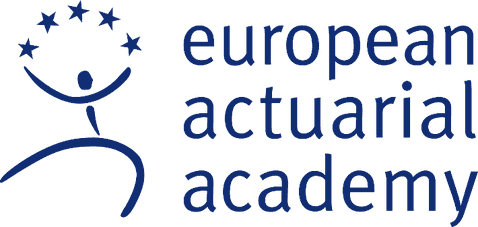

<h1 style="color:#0F2B72;">Fit4AI compact</h1>
<h2 style="color:#0F2B72;">Module 7 – Generative Artificial Intelligence – companion notebook</h2>
<h3 style="color:#0F2B72;">From a single neuron to GPT</h3>
<div style="border:0px; background-color:#0F2B72; width:100%; height:1px;">&nbsp;</div>
<h4 style="color:#0F2B72;" class="unlisted unnumbered">EAA Inhouse Seminar SAV | Zurich, 19/20 November 2026</h4>
<p style="color:#0F2B72;">Dr Simon Hatzesberger<br>Jupyter Notebook (Python)</p>

*A hands-on companion notebook for actuaries.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/fit4ai-compact-20261119/blob/main/Fit4AI_7_GenAI_Companion.ipynb)

Repository: [simonhatzesberger/fit4ai-compact-20261119](https://github.com/simonhatzesberger/fit4ai-compact-20261119) – code under the [MIT License](https://github.com/simonhatzesberger/fit4ai-compact-20261119/blob/main/LICENSE).

Large language models such as ChatGPT can feel like magic. This notebook removes the magic by **building the core machinery yourself**, one transparent step at a time. We deliberately favour small, readable [NumPy](https://numpy.org/) implementations over black-box framework calls, so that you can *see* every weighted sum, every gradient and every probability.

The four parts build on one another exactly like the real systems do, and they follow the sections of the Module 7 slides:

1. **Artificial neural networks** – the learning engine underneath everything else. We train the small network from the slides (section *ANN training*) *by hand* and watch the loss fall.
2. **Word embeddings (skip-gram / word2vec)** – how words become vectors whose geometry captures meaning (section *Embeddings*).
3. **The language-modelling head** – how a vector of scores becomes a probability distribution over the next token, and how *temperature*, *top-k* and *top-p* reshape that choice (section *Transformer*, building blocks (IV) and (V)).
4. **GPT-2 (medium)** – a real model with about 355 million parameters that stitches all of the above together and generates text token by token (section *Generative models*); on the way we count its parameters and look at its tokeniser (section *Tokenisation*).

Nothing here assumes prior machine-learning knowledge – only the comfort with vectors, derivatives and probability that every actuary already has. Where it helps, we frame ideas in insurance terms (premiums, claims, mortality, reserves).

> **How to use this notebook.** Run the cells top to bottom (**Shift + Enter**). Each section ends with an exercise; click *“Show solution”* to reveal a worked answer once you have tried it yourself.

## Contents <a id="contents"></a>

1. [Artificial neural networks from scratch](#ann)
2. [Word embeddings: the skip-gram model (word2vec)](#word2vec)
3. [The language-modelling head: turning scores into the next token](#lmhead)
4. [GPT-2: a real generative model, end to end](#gpt2)
5. [Summary and further reading](#summary)

## Learning objectives <a id="objectives"></a>

By the end of this notebook you will be able to:

- **Explain** how a neural network turns inputs into a prediction (the *forward pass*) and how it learns from its mistakes (*backpropagation* and *gradient descent*).
- **Reproduce**, by hand and in code, a full training step of a small network and read off every intermediate quantity – with exactly the numbers on the slides.
- **Describe** how words are represented as vectors, and **train** a miniature word2vec model whose geometry you can visualise in 2-D.
- **Distinguish** greedy, top-k, top-p and temperature decoding, and **predict** how each one reshapes the model’s choice of the next token.
- **Inspect** a real language model: where GPT-2’s 355 million parameters sit and how its byte-pair encoding splits English and German words into tokens.
- **Generate** text with GPT-2 and **control** its style and length through the very same decoding knobs you built by hand.
- **Calibrate** realistic expectations of what today’s generative AI can and cannot do.

## Setup <a id="setup"></a>

The cell below prepares the environment. On **Google Colab** all packages used here (NumPy, Matplotlib, seaborn, ipywidgets, PyTorch, transformers) are preinstalled; the cell only installs `transformers` if it should be missing and switches on Colab’s support for the interactive sliders. On a **local** machine it assumes that you have run `pip install -r requirements.txt` inside your virtual environment, with the file [`requirements.txt`](https://github.com/simonhatzesberger/fit4ai-compact-20261119/blob/main/requirements.txt) from the repository (see its [README](https://github.com/simonhatzesberger/fit4ai-compact-20261119#readme)).

It also fixes a random seed for reproducibility and sets a consistent plotting style in the EAA colours. Section 4 additionally downloads **GPT-2 medium** (about 1.5 GB) the first time you run it – everything before that runs in seconds on a normal laptop.

In [1]:
# --- Environment detection: Colab vs. local -------------------------------
# Locally, install the packages first:  pip install -r requirements.txt
import importlib.util
import subprocess
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Colab ships every package used here; install transformers only if it is missing
    # (no version pins, so Colab's preinstalled packages stay unchanged).
    if importlib.util.find_spec("transformers") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"],
                       check=True)
    # Let Colab render the ipywidgets sliders of Sections 1-3.
    from google.colab import output
    output.enable_custom_widget_manager()

# --- Core imports ----------------------------------------------------------
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ipywidgets powers the interactive sliders in Sections 1-3.
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown

# --- Reproducibility -------------------------------------------------------
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# --- House style (EAA navy and cyan, red / green accents) -----------------
PRIMARY      = "#0F2B72"   # EAA navy
ACCENT_RED   = "#C0504D"   # business red
ACCENT_GREEN = "#4E7C59"   # forest green
ACCENT_CYAN  = "#009CDB"   # EAA cyan
GRAY_TEXT    = "#404040"

sns.set_theme(
    style="whitegrid",
    palette=[PRIMARY, ACCENT_RED, ACCENT_GREEN, ACCENT_CYAN, "#9C7A7A"],
    rc={
        "axes.edgecolor": GRAY_TEXT, "axes.labelcolor": GRAY_TEXT,
        "xtick.color": GRAY_TEXT, "ytick.color": GRAY_TEXT,
        "axes.titlecolor": PRIMARY, "axes.titleweight": "bold",
        "grid.color": "#E5E5E5", "figure.facecolor": "white", "axes.facecolor": "white",
    },
)

print(f"Setup complete. Environment: {'Google Colab' if IN_COLAB else 'local'}.")
print(f"NumPy {np.__version__}. Random seed fixed at {SEED}.")

Setup complete. Environment: local.
NumPy 2.4.6. Random seed fixed at 42.


## 1. Artificial neural networks from scratch <a id="ann"></a>

Everything in modern generative AI – embeddings, transformers, GPT – is built from **artificial neural networks (ANNs)**. So we start here, with the smallest network that still shows all the moving parts, and we train it *entirely by hand in NumPy*.

**A single neuron** does two things:

1. it forms a **weighted sum** of its inputs plus a **bias**, $z = w_1 x_1 + w_2 x_2 + \dots + b$;
2. it passes that sum through a non-linear **activation function** $f$, giving the output $a = f(z)$.

The bias $b$ plays exactly the role of the **intercept in a linear regression**: it shifts the neuron’s input before the activation decides whether (and how strongly) the neuron “fires”. A network is just many such neurons arranged in **layers**, with the outputs of one layer feeding the next. Training means **adjusting the weights** so the network’s predictions match the targets.

### 1.1 The network and the data

We use the fully connected **2-3-1** network of the slides (slide *Example* in the section *ANN training*): two inputs (neurons **A** and **B**), one hidden layer of three neurons (**C**, **D**, **E**) and a single output neuron **F**. It approximates a function $f:\mathbb{R}^2 \to \mathbb{R}$, so this is a **regression** problem.

- **Hidden layer** uses the **ReLU** activation $\operatorname{ReLU}(z)=\max(z, 0)$ – cheap, and the source of the network’s non-linearity.
- **Output layer** uses the **identity** activation (no squashing), because the target is a real number.
- **Loss**: mean squared error $\;\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$ – with $n = 2$ exactly the slides’ $\frac{1}{2}\sum_{i=1}^{2}(\hat{Y}_i - Y_i)^2$.

We have just **two training points** – enough to see every number by eye:

$$x_1 = (0.8;\ 0.3),\ y_1 = 1 \qquad\qquad x_2 = (-0.4;\ 0.5),\ y_2 = 2$$

The initial weights (as if drawn at random) are those of the slide *Random assignment of starting weights*:

| hidden neuron | bias | weight on input A | weight on input B |
|:---:|:---:|:---:|:---:|
| **C** | 0.3 | 0.5 | 0.2 |
| **D** | 0.2 | −0.7 | −0.1 |
| **E** | −0.4 | 0.4 | 1.4 |

and the output neuron **F** has bias $1.0$ and weights $(0.8;\ {-0.4};\ 0.3)$ on $(C, D, E)$.

**Note on notation – biases folded into the weights.** The slide *Backpropagation, or how the network “learns”* writes this network more compactly in **matrix notation**: it puts a constant **1** in front of every input vector and moves each bias into its weight matrix as an extra first row:

$$\big(1,\ x^{(A)},\ x^{(B)}\big)\,W_1^{\text{slides}}, \qquad
W_1^{\text{slides}} = \begin{pmatrix} 0.3 & 0.2 & -0.4 \\ 0.5 & -0.7 & 0.4 \\ 0.2 & -0.1 & 1.4 \end{pmatrix} = \begin{pmatrix} b_1 \\ W_1 \end{pmatrix}, \qquad
W_2^{\text{slides}} = \begin{pmatrix} 1.0 \\ 0.8 \\ -0.4 \\ 0.3 \end{pmatrix} = \begin{pmatrix} b_2 \\ W_2 \end{pmatrix}.$$

Because $(1,\ x)\begin{pmatrix} b_1 \\ W_1 \end{pmatrix} = x\,W_1 + b_1$, the slide notation $\operatorname{ReLU}\big((1,\ x)\,W_1^{\text{slides}}\big)$ is **equivalent** to $\operatorname{ReLU}(x\,W_1 + b_1)$ with the separate biases $b_1$, $b_2$ used in this notebook; likewise $(1,\ h)\,W_2^{\text{slides}} = h\,W_2 + b_2$ at the output, where $h = (a_C, a_D, a_E)$. Both notations give identical numbers, e.g. $\hat{y}_1 = 1.71$ and $\hat{y}_2 = 1.03$. We keep $b_1$ and $b_2$ separate in the code because this makes their gradients visible in the backpropagation step; at the end of Section 1.3 we stack them again and print the matrices exactly as they appear on the slides.

In [2]:
# Two training points: features in R^2, target in R.
X = np.array([[ 0.8, 0.3],
              [-0.4, 0.5]])
y = np.array([1.0, 2.0])

# Initial parameters of the 2-3-1 network.
# W1 columns are the hidden neurons C, D, E; rows are the two inputs A, B.
W1 = np.array([[0.5, -0.7, 0.4],     # input A -> (C, D, E)
               [0.2, -0.1, 1.4]])    # input B -> (C, D, E)
b1 = np.array([0.3, 0.2, -0.4])      # hidden biases (C, D, E)
W2 = np.array([0.8, -0.4, 0.3])      # hidden (C, D, E) -> output F
b2 = 1.0                             # output bias

def relu(z):
    return np.maximum(0.0, z)

print("X =\n", X)
print("y =", y)
print("Hidden weights W1 (cols = C, D, E):\n", W1)

X =
 [[ 0.8  0.3]
 [-0.4  0.5]]
y = [1. 2.]
Hidden weights W1 (cols = C, D, E):
 [[ 0.5 -0.7  0.4]
 [ 0.2 -0.1  1.4]]


### 1.2 The forward pass

The forward pass simply evaluates the network left to right. For one input $x=(x^{(A)},x^{(B)})$ and hidden neuron $C$:

$$a_C = \operatorname{ReLU}\big(b_C + w^{C}_A\, x^{(A)} + w^{C}_B\, x^{(B)}\big).$$

We do this for all three hidden neurons, then combine them at the output:

$$\hat{y} = b_F + w^{F}_C\, a_C + w^{F}_D\, a_D + w^{F}_E\, a_E.$$

In matrix form this is just two lines of NumPy. Let us run it on **both** training points and print every intermediate number – compare with the slides *Forward pass of $x_1$* and *Forward pass of $x_2$*.

In [3]:
def forward(X, W1, b1, W2, b2, verbose=False):
    Z1 = X @ W1 + b1          # hidden pre-activations, shape (n, 3)
    H  = relu(Z1)             # hidden activations after ReLU
    yhat = H @ W2 + b2        # output neuron, identity activation, shape (n,)
    if verbose:
        names = ["C", "D", "E"]
        for i in range(X.shape[0]):
            print(f"point {i+1}:  x = {X[i]},  target y = {y[i]}")
            for j, nm in enumerate(names):
                print(f"   z_{nm} = {Z1[i, j]:+.3f}  ->  ReLU  ->  "
                      f"a_{nm} = {H[i, j]:.3f}")
            print(f"   prediction  yhat_{i+1} = {yhat[i]:.3f}\n")
    return Z1, H, yhat

Z1, H, yhat = forward(X, W1, b1, W2, b2, verbose=True)

point 1:  x = [0.8 0.3],  target y = 1.0
   z_C = +0.760  ->  ReLU  ->  a_C = 0.760
   z_D = -0.390  ->  ReLU  ->  a_D = 0.000
   z_E = +0.340  ->  ReLU  ->  a_E = 0.340
   prediction  yhat_1 = 1.710

point 2:  x = [-0.4  0.5],  target y = 2.0
   z_C = +0.200  ->  ReLU  ->  a_C = 0.200
   z_D = +0.430  ->  ReLU  ->  a_D = 0.430
   z_E = +0.140  ->  ReLU  ->  a_E = 0.140
   prediction  yhat_2 = 1.030



Notice neuron **D** for the first point: its weighted sum is negative ($z_D = 0.2 - 0.8\cdot0.7 - 0.3\cdot0.1 = -0.39$), so ReLU clamps it to **0**. That clamping is the network’s *only* source of non-linearity – without it, the stacked linear layers would collapse into a single linear map and the network could never bend to fit anything interesting.

Now we score how wrong the predictions are.

In [4]:
def mse(yhat, y):
    return float(np.mean((yhat - y) ** 2))

loss0 = mse(yhat, y)
print("predictions:", np.round(yhat, 3), "  targets:", y)
print(f"training loss (MSE) = {loss0:.4f}")

predictions: [1.71 1.03]   targets: [1. 2.]
training loss (MSE) = 0.7225


### 1.3 Backpropagation: one full step

Learning means nudging every weight in the direction that **reduces the loss**. The size of that nudge is the **gradient** of the loss with respect to that weight, and we obtain all the gradients in one backward sweep using the **chain rule** – this is *backpropagation* (slide *Optimisation*).

Working from the output backwards:

$$\frac{\partial \mathcal{L}}{\partial \hat{y}} = \frac{2}{n}(\hat{y}-y), \qquad
\frac{\partial \mathcal{L}}{\partial W_2} = H^\top \frac{\partial \mathcal{L}}{\partial \hat{y}}, \qquad
\frac{\partial \mathcal{L}}{\partial b_2} = \sum_i \frac{\partial \mathcal{L}}{\partial \hat{y}_i}.$$

We then push the gradient back through the output weights and the ReLU (whose derivative is $1$ where $z>0$ and $0$ otherwise) to reach the hidden weights $W_1, b_1$. With $n=2$ points the factor $2/n=1$, so the per-point signal is simply $(\hat{y}-y)$.

In [5]:
n = len(y)
grad_yhat = (2.0 / n) * (yhat - y)      # dL/dyhat ; with n=2 this is just (yhat - y)
gW2 = H.T @ grad_yhat                    # dL/dW2
gb2 = grad_yhat.sum()                    # dL/db2
grad_H  = np.outer(grad_yhat, W2)        # gradient into the hidden activations
grad_Z1 = grad_H * (Z1 > 0)              # back through ReLU: ReLU'(z) = 1 if z>0 else 0
gW1 = X.T @ grad_Z1                      # dL/dW1
gb1 = grad_Z1.sum(axis=0)                # dL/db1

print("dL/dyhat =", np.round(grad_yhat, 3))
print("dL/dW2   =", np.round(gW2, 3))
print("dL/db2   =", round(gb2, 3))
print("dL/dW1   =\n", np.round(gW1, 3))
print("dL/db1   =", np.round(gb1, 3))

dL/dyhat = [ 0.71 -0.97]
dL/dW2   = [ 0.346 -0.417  0.106]
dL/db2   = -0.26
dL/dW1   =
 [[ 0.765 -0.155  0.287]
 [-0.218  0.194 -0.082]]
dL/db1   = [-0.208  0.388 -0.078]


Each weight now steps a little way **downhill**: $w \leftarrow w - \varepsilon\,\dfrac{\partial \mathcal{L}}{\partial w}$, where the **learning rate** $\varepsilon$ controls the step size. Let us take one step with $\varepsilon = 0.3$, as on the slides, and watch the predictions move towards their targets.

In [6]:
lr = 0.3
W1_new = W1 - lr * gW1
b1_new = b1 - lr * gb1
W2_new = W2 - lr * gW2
b2_new = b2 - lr * gb2

_, _, yhat_new = forward(X, W1_new, b1_new, W2_new, b2_new)
print("W2:", np.round(W2, 2), "->", np.round(W2_new, 2))
print("b2:", round(b2, 2), "->", round(b2_new, 2))
print("predictions:", np.round(yhat, 2), "->", np.round(yhat_new, 2),
      " (targets", y, ")")
print(f"loss: {loss0:.4f} -> {mse(yhat_new, y):.4f}")

W2: [ 0.8 -0.4  0.3] -> [ 0.7  -0.27  0.27]
b2: 1.0 -> 1.08
predictions: [1.71 1.03] -> [1.62 1.33]  (targets [1. 2.] )
loss: 0.7225 -> 0.4147


**Check against the slides (folded-bias notation).** Stacking bias and weights as on the slides gives exactly the matrices shown there – the hidden values and predictions (slide *Backpropagation, or how the network “learns”*), the gradients $\partial\mathcal{L}/\partial W_2$ and $\partial\mathcal{L}/\partial W_1$ and the weights after the update (slides *Optimisation in the example*). The helper `slide_fmt` rounds to two decimals, as the slides do.

In [7]:
def slide_fmt(M, nd=2):
    # Matrix or vector rounded to nd decimals, one row per line (as on the slides).
    M = np.atleast_2d(np.round(M, nd))
    fmt = [[f"{v:>6.{nd}f}".replace("-0.00", " 0.00") for v in row] for row in M]
    return "\n".join("   " + "  ".join(r) for r in fmt)

# Slide notation: first row = bias, then the weights
W1_slides, W2_slides = np.vstack([b1, W1]), np.r_[b2, W2]
gW1_slides, gW2_slides = np.vstack([gb1, gW1]), np.r_[gb2, gW2]

# The same forward pass in slide notation: ReLU((1, x) W1), then (1, h) W2
X1 = np.c_[np.ones(len(X)), X]
H1 = np.c_[np.ones(len(X)), relu(X1 @ W1_slides)]
print("values at C, D, E = ReLU((1, x) W1)  (rows = training points):\n"
      + slide_fmt(H1[:, 1:]))
print("values at F = (1, h) W2:", slide_fmt(H1 @ W2_slides).strip())
print("\ndL/dW2 (slide: -0.26 / 0.35 / -0.42 / 0.11):\n"
      + slide_fmt(gW2_slides[:, None]))
print("\ndL/dW1 (slide, 3x3 incl. bias row):\n" + slide_fmt(gW1_slides))
print("\nW2 new (slide: 1.08 / 0.70 / -0.27 / 0.27):\n"
      + slide_fmt(np.r_[b2_new, W2_new][:, None]))
print("\nW1 new (slide):\n" + slide_fmt(np.vstack([b1_new, W1_new])))

values at C, D, E = ReLU((1, x) W1)  (rows = training points):
     0.76    0.00    0.34
     0.20    0.43    0.14
values at F = (1, h) W2: 1.71    1.03

dL/dW2 (slide: -0.26 / 0.35 / -0.42 / 0.11):
    -0.26
     0.35
    -0.42
     0.11

dL/dW1 (slide, 3x3 incl. bias row):
    -0.21    0.39   -0.08
     0.76   -0.16    0.29
    -0.22    0.19   -0.08

W2 new (slide: 1.08 / 0.70 / -0.27 / 0.27):
     1.08
     0.70
    -0.27
     0.27

W1 new (slide):
     0.36    0.08   -0.38
     0.27   -0.65    0.31
     0.27   -0.16    1.42


A worked entry: row 2, column 1 of $\partial\mathcal{L}/\partial W_1$ (input A → neuron C) collects the error signal $(\hat{y}_i - y_i)\cdot w^F_C$ of neuron C at both training points – $0.71 \cdot 0.8 = 0.568$ and $-0.97 \cdot 0.8 = -0.776$ – weighted with the input values of A:

$$0.8 \cdot 0.568 + (-0.4) \cdot (-0.776) = 0.7648 \approx 0.76.$$

(Section 1.3 printed it with three decimals as 0.765; rounding that value a second time would give 0.77 – a classic double-rounding trap. Always round from the exact value.)

One step already cut the loss from **0.7225** to about **0.415**. Repeating this – forward pass, backward pass, weight update – is the whole of training.

### 1.4 Training over many iterations

We wrap the loop in a `train` function. To make Exercise 1 easy, it also accepts a choice of activation function (ReLU, tanh or sigmoid) and lets you pass your own data and starting weights.

In [8]:
# Each activation is a (function, derivative) pair.
ACTIVATIONS = {
    "relu":    (lambda z: np.maximum(0.0, z), lambda z: (z > 0).astype(float)),
    "tanh":    (lambda z: np.tanh(z),         lambda z: 1.0 - np.tanh(z) ** 2),
    "sigmoid": (lambda z: 1.0 / (1.0 + np.exp(-z)),
                lambda z: (1.0 / (1.0 + np.exp(-z)))
                          * (1.0 - 1.0 / (1.0 + np.exp(-z)))),
}

def train(n_iter=40, lr=0.3, activation="relu",
          X=X, y=y, W1=W1, b1=b1, W2=W2, b2=b2):
    '''Full-batch gradient descent on a 2-h-1 network. Returns (loss_history, params).
    The data and initial weights default to the worked example above.'''
    act, dact = ACTIVATIONS[activation]
    W1, b1, W2, b2 = W1.copy(), b1.copy(), W2.copy(), float(b2)
    n = len(y)
    losses = []
    for _ in range(n_iter):
        Z1 = X @ W1 + b1
        H  = act(Z1)
        yh = H @ W2 + b2
        losses.append(float(np.mean((yh - y) ** 2)))
        grad_yhat = (2.0 / n) * (yh - y)
        gW2 = H.T @ grad_yhat
        gb2 = grad_yhat.sum()
        grad_Z1 = np.outer(grad_yhat, W2) * dact(Z1)
        gW1 = X.T @ grad_Z1
        gb1 = grad_Z1.sum(axis=0)
        W2 -= lr * gW2; b2 -= lr * gb2
        W1 -= lr * gW1; b1 -= lr * gb1
    return losses, (W1, b1, W2, b2)

losses, _ = train(n_iter=40, lr=0.3, activation="relu")
print("loss at iterations 0..5:", ", ".join(f"{l:.4f}" for l in losses[:6]))

loss at iterations 0..5: 0.7225, 0.4147, 0.3001, 0.2307, 0.1781, 0.1339


Rounded to three decimals, these are the values in the table on the slide *Multiple passes of the training points (Python)*: 0.723 → 0.415 → 0.300 → 0.231 → 0.178 → 0.134.

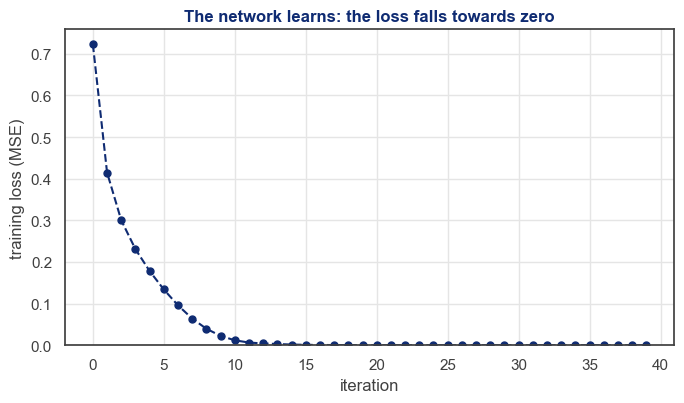

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(range(len(losses)), losses, "o--", color=PRIMARY, ms=5, lw=1.5)
ax.set_xlabel("iteration")
ax.set_ylabel("training loss (MSE)")
ax.set_title("The network learns: the loss falls towards zero")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

### 1.5 Interactive: learning rate and number of iterations

The **learning rate** is the single most important training knob. Too small and learning crawls; too large and the steps overshoot, making the loss bounce or even explode. Drag the sliders and watch the loss curve react.

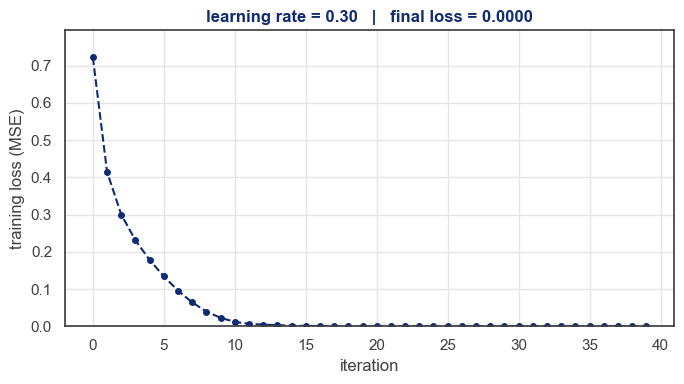

interactive(children=(FloatSlider(value=0.3, description='lr', max=1.5, min=0.01, step=0.01), IntSlider(value=…

In [10]:
def ann_loss_demo(learning_rate=0.3, iterations=40):
    hist, _ = train(n_iter=int(iterations), lr=float(learning_rate), activation="relu")
    hist = np.array(hist, dtype=float)
    finite = hist[np.isfinite(hist)]
    ymax = float(finite.max()) * 1.1 if finite.size else 1.0
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(len(hist)), hist, "o--", color=PRIMARY, ms=4, lw=1.5)
    ax.set_xlabel("iteration")
    ax.set_ylabel("training loss (MSE)")
    ax.set_ylim(0, max(ymax, 1e-3))
    ax.set_title(f"learning rate = {learning_rate:.2f}   |   "
                 f"final loss = {hist[-1]:.4f}")
    fig.tight_layout()
    plt.show()

# Static example first, so a figure shows even on a non-interactive viewer...
ann_loss_demo(0.3, 40)

# ...then drag the sliders below. Try a learning rate above ~1.0 to see it overshoot.
interact(
    ann_loss_demo,
    learning_rate=FloatSlider(value=0.3, min=0.01, max=1.5, step=0.01,
                              description="lr"),
    iterations=IntSlider(value=40, min=1, max=200, step=1, description="iters"),
);

### Exercise 1

1. **Change the activation.** Re-train the two-point network with `"tanh"` and `"sigmoid"` instead of `"relu"`. Which converges fastest here, and which is clearly slowest? (Hint: compare `losses[0]`, `losses[-1]` and the first iteration at which the loss drops below 0.0001.)
2. **A tiny actuarial application.** Build a small synthetic dataset that predicts a (standardised) **claim cost** from two features, *age* and *BMI*, with a deliberately non-linear true relationship. Re-use `train(...)` – it already accepts your own `X`, `y` and starting weights – and show that the loss falls.

Try it yourself before revealing the solution.

<details>
<summary><b>Show solution</b></summary>

```python
# (1) Same two points, three activations
for actf in ["relu", "tanh", "sigmoid"]:
    L, _ = train(n_iter=60, lr=0.3, activation=actf)
    hits = [i for i, v in enumerate(L) if v < 1e-4]    # iterations with loss < 0.0001
    print(f"{actf:8s}: loss[0] = {L[0]:.3f}   loss[-1] = {L[-1]:.4f}   "
          f"loss < 0.0001 from iteration: {hits[0] if hits else 'never'}")
# ReLU and tanh drive the loss to practically 0; tanh is fastest (below 0.0001
# from iteration 18, ReLU from iteration 21). Sigmoid is clearly slowest
# (0.362 -> 0.038 after 60 iterations) because its gradients are small for
# these inputs (a hint of the "vanishing gradient" problem).

# (2) A tiny synthetic actuarial regression: claim cost from age and BMI
g = np.random.default_rng(0)
age = g.uniform(20, 70, 60)
bmi = g.uniform(18, 40, 60)
# non-linear "truth": a U-shape in age plus a kink in BMI, with noise
cost = (0.03 * (age - 45) ** 2 / 10 + 0.5 * np.maximum(bmi - 25, 0)
        + g.normal(0, 0.3, 60))

# standardise inputs and target (neural nets train far better on standardised data)
Xa = np.c_[(age - age.mean()) / age.std(), (bmi - bmi.mean()) / bmi.std()]
ya = (cost - cost.mean()) / cost.std()

# fresh random starting weights for the 2-3-1 net
gw = np.random.default_rng(1)
W1b, b1b = gw.normal(0, 0.5, (2, 3)), np.zeros(3)
W2b, b2b = gw.normal(0, 0.5, 3), 0.0

La, _ = train(n_iter=400, lr=0.05, activation="tanh",
              X=Xa, y=ya, W1=W1b, b1=b1b, W2=W2b, b2=b2b)
print(f"\nactuarial fit: loss {La[0]:.3f} -> {La[-1]:.3f}")
```

</details>

In [11]:
# (1) Same two points, three activations
for actf in ["relu", "tanh", "sigmoid"]:
    L, _ = train(n_iter=60, lr=0.3, activation=actf)
    hits = [i for i, v in enumerate(L) if v < 1e-4]    # iterations with loss < 0.0001
    print(f"{actf:8s}: loss[0] = {L[0]:.3f}   loss[-1] = {L[-1]:.4f}   "
          f"loss < 0.0001 from iteration: {hits[0] if hits else 'never'}")
# ReLU and tanh drive the loss to practically 0; tanh is fastest (below 0.0001
# from iteration 18, ReLU from iteration 21). Sigmoid is clearly slowest
# (0.362 -> 0.038 after 60 iterations) because its gradients are small for
# these inputs (a hint of the "vanishing gradient" problem).

relu    : loss[0] = 0.722   loss[-1] = 0.0000   loss < 0.0001 from iteration: 21
tanh    : loss[0] = 0.752   loss[-1] = 0.0000   loss < 0.0001 from iteration: 18
sigmoid : loss[0] = 0.362   loss[-1] = 0.0384   loss < 0.0001 from iteration: never


## 2. Word embeddings: the skip-gram model (word2vec) <a id="word2vec"></a>

A neural network only speaks numbers, but text is made of words. **Embeddings** bridge the gap: every word (more generally, every token) becomes a dense vector, and the *geometry* of those vectors captures *meaning*. Words used in similar ways end up close together; directions in the space line up with analogies (the famous *king − man + woman ≈ queen*).

The guiding idea is the **distributional hypothesis** – *“you shall know a word by the company it keeps”* (Firth, 1957). A word’s meaning is revealed by the words that surround it. As on the slides *Embeddings*, we measure closeness with the **cosine similarity** of two vectors $v, w$:

$$\operatorname{sim}(v, w) = \frac{v \cdot w}{\lVert v\rVert\,\lVert w\rVert} = \cos\theta.$$

We will *train* embeddings with the **skip-gram model with negative sampling** – the algorithm behind **word2vec** (slide *Excursus: Skip-gram learns from local contexts*) – entirely from scratch, on a small insurance corpus.

### 2.1 A tiny corpus and its training pairs

Our corpus is twenty short sentences clustered around four insurance themes: **motor**, **life/mortality**, **health** and **pricing**. We drop a handful of very frequent **stop-words** (*the, a, and, …*) that carry little meaning and otherwise dominate the statistics. From what remains we extract **(target, context) pairs**: for each word (the *target*), every other word within a **context window** of $k$ positions to the left and right counts as a *context* word.

Unlike real language models, we simply split the text into words here, so *actuary* and *actuaries* are two unrelated tokens – a small example of why modern tokenisers split words into subword tokens (slides *Tokenisation*; GPT-2’s tokeniser follows in Section 4.3).

In [12]:
corpus = [
    # motor
    "the driver caused a car accident on the motorway",
    "the motor policy covers vehicle collision and theft",
    "a careful driver lowers the risk of a car accident",
    "the vehicle damage from the collision was expensive",
    "the car insurer assessed the accident and the motor claim",
    # life / mortality
    "the life insurer used a mortality table to price the annuity",
    "actuaries model mortality and longevity for life insurance",
    "the annuity pays the pensioner until death",
    "longevity risk threatens every pension and annuity",
    "the life policy pays a benefit on death",
    # health
    "the health plan reimburses hospital and medical costs",
    "the patient claimed the medical treatment expense",
    "a chronic illness raises future hospital and medical costs",
    "the health insurer reviewed the hospital treatment claim",
    "preventive care reduces illness and medical costs",
    # pricing / bridge themes
    "the actuary set the premium from the estimated risk",
    "higher risk leads to a higher insurance premium",
    "the insurer holds a reserve for every open claim",
    "the actuary priced the policy and the premium",
    "a fair premium reflects the underlying claim risk",
]

STOPWORDS = {"the", "a", "an", "and", "on", "to", "for", "of", "from",
             "until", "was", "every", "in", "at", "is", "it", "this",
             "that", "with", "by", "or", "up"}

def tokenize(s):
    return [w for w in re.findall(r"[a-z]+", s.lower()) if w not in STOPWORDS]

sentences = [tokenize(s) for s in corpus]
vocab = sorted({w for s in sentences for w in s})
word2id = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"{len(corpus)} sentences, vocabulary size |V| = {V} (stop-words removed)")
print("some words:", vocab[:12])

20 sentences, vocabulary size |V| = 66 (stop-words removed)
some words: ['accident', 'actuaries', 'actuary', 'annuity', 'assessed', 'benefit', 'car', 'care', 'careful', 'caused', 'chronic', 'claim']


In [13]:
def make_pairs(sentences, window=2):
    pairs = []
    for s in sentences:
        ids = [word2id[w] for w in s]
        for i, center in enumerate(ids):
            lo, hi = max(0, i - window), min(len(ids), i + window + 1)
            for j in range(lo, hi):
                if j != i:
                    pairs.append((center, ids[j]))
    return pairs

pairs = make_pairs(sentences, window=2)
print(f"{len(pairs)} (target, context) pairs with context window k = 2")
print("examples:", [(vocab[c], vocab[o]) for c, o in pairs[:6]])

320 (target, context) pairs with context window k = 2
examples: [('driver', 'caused'), ('driver', 'car'), ('caused', 'driver'), ('caused', 'car'), ('caused', 'accident'), ('car', 'driver')]


### 2.2 The model: two vectors per word, and negative sampling

Skip-gram gives every word **two** vectors: one in its role as a *target* word (stored in matrix $W$) and one as a *context* word (matrix $C$). We train a tiny binary classifier that estimates whether a pair $(w, c)$ is a *real* target–context pair:

$$P(+\mid w, c) = \sigma(\,v_w \cdot u_c\,), \qquad \sigma(x) = \frac{1}{1 + e^{-x}}.$$

Real pairs (from the corpus) should score near 1; random “**negative**” pairs (a target word paired with a word drawn at random) should score near 0. This is **negative sampling**: instead of comparing against the whole vocabulary, we contrast each true pair with a handful of random ones. Below we run **one** update by hand and print every quantity.

In [14]:
# Unigram^0.75 distribution for drawing negative samples (the word2vec trick).
counts = np.zeros(V)
for s in sentences:
    for w in s:
        counts[word2id[w]] += 1
noise = counts ** 0.75
noise /= noise.sum()

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

# --- ONE manual skip-gram update, fully printed ---
demo = np.random.default_rng(SEED)
W0 = demo.normal(0, 0.1, (V, 16))   # target embeddings
C0 = demo.normal(0, 0.1, (V, 16))   # context embeddings
center, context = word2id["premium"], word2id["risk"]
negs = demo.choice(V, size=3, p=noise)
vc, uo, Un = W0[center], C0[context], C0[negs]
s_pos = sigmoid(vc @ uo)
s_neg = sigmoid(Un @ vc)
print(f"target = 'premium',  positive context = 'risk',  "
      f"negatives = {[vocab[i] for i in negs]}")
print(f"  P(+ | premium, risk)      = {s_pos:.3f}   (we want this near 1)")
print(f"  P(+ | premium, negatives) = {np.round(s_neg, 3)}   (we want these near 0)")
grad_vc = (s_pos - 1.0) * uo + (s_neg[:, None] * Un).sum(0)
print(f"  -> gradient pushes 'premium' towards 'risk' and away from the negatives "
      f"(|grad| = {np.linalg.norm(grad_vc):.3f})")

target = 'premium',  positive context = 'risk',  negatives = ['insurance', 'damage', 'higher']
  P(+ | premium, risk)      = 0.506   (we want this near 1)
  P(+ | premium, negatives) = [0.496 0.504 0.503]   (we want these near 0)
  -> gradient pushes 'premium' towards 'risk' and away from the negatives (|grad| = 0.341)


### 2.3 Training the embeddings

`fit_word2vec` repeats that update over all pairs for many epochs. As is common in the word2vec literature, the **final embedding** of a word is the **sum of its target and context rows**, $W + C$.

How many dimensions? **Two** turn out to be far too cramped – the vectors collapse onto a single direction and every word looks similar to every other. Real systems use **50 to 1,000** dimensions (slide *Count-based embeddings vs. word2vec*). We train in a modest **16** and then *project* down to 2-D with **PCA** (principal component analysis) just for the picture.

In [15]:
def fit_word2vec(window=2, n_neg=5, dim=16, lr=0.05, epochs=300, seed=2):
    # seed=2 simply gives a tidy 2-D projection; the neighbourhoods hardly depend
    # on the seed.
    g = np.random.default_rng(seed)
    W = g.normal(0, 0.1, (V, dim))
    C = g.normal(0, 0.1, (V, dim))
    training_pairs = make_pairs(sentences, window)
    for _ in range(epochs):
        for idx in g.permutation(len(training_pairs)):
            c, o = training_pairs[idx]
            negs = g.choice(V, size=n_neg, p=noise)
            vc = W[c].copy()
            uo, Un = C[o], C[negs]
            s_pos = sigmoid(vc @ uo)
            s_neg = sigmoid(Un @ vc)
            grad_vc = (s_pos - 1.0) * uo + (s_neg[:, None] * Un).sum(0)
            C[o]    -= lr * ((s_pos - 1.0) * vc)
            C[negs] -= lr * (s_neg[:, None] * vc)
            W[c]    -= lr * grad_vc
    return W + C    # final embedding = target + context row

emb = fit_word2vec(dim=16, window=2, epochs=300)
print(f"embedding matrix shape: {emb.shape}  ({V} words x 16 dimensions)")

embedding matrix shape: (66, 16)  (66 words x 16 dimensions)


In [16]:
def unit_rows(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)

def nearest(word, emb, k=5):
    E = unit_rows(emb)
    sims = E @ E[word2id[word]]
    order = np.argsort(-sims)
    return [(vocab[j], round(float(sims[j]), 2))
            for j in order if j != word2id[word]][:k]

for w in ["premium", "mortality", "hospital", "car", "death"]:
    print(f"{w:10s} nearest -> {nearest(w, emb)}")

premium    nearest -> [('set', 0.86), ('actuary', 0.84), ('estimated', 0.8), ('priced', 0.79), ('fair', 0.77)]
mortality  nearest -> [('used', 0.87), ('model', 0.83), ('actuaries', 0.81), ('table', 0.8), ('longevity', 0.73)]
hospital   nearest -> [('treatment', 0.84), ('costs', 0.79), ('expense', 0.79), ('reviewed', 0.77), ('medical', 0.76)]
car        nearest -> [('caused', 0.95), ('accident', 0.89), ('motorway', 0.89), ('assessed', 0.8), ('driver', 0.77)]
death      nearest -> [('pensioner', 0.95), ('benefit', 0.94), ('pays', 0.92), ('annuity', 0.68), ('policy', 0.51)]


The neighbours respect the themes: *premium* sits with *actuary*, *estimated* and *priced*; *mortality* with *actuaries*, *table* and *longevity*; *hospital* with *treatment*, *costs* and *medical*; *car* with *accident*, *motorway* and *driver* – all learned purely from twenty sentences. Some neighbours are simply words from the same sentence (*set*, *used*, *caused*): with so little text, sharing a sentence is almost all the evidence the model has.

### 2.4 Visualising the embedding space

PCA finds the two directions along which the 16-dimensional embeddings vary most, and projects every word onto them. Plotting a few representative words per theme shows the geometry: same-theme words – which keep similar company – land near one another (compare the slide *Example: 2-dimensional embeddings*). Life and health form clear clusters; motor and pricing overlap, because bridge words such as *claim*, *risk* and *policy* occur in both themes (“motor claim”, “the risk of a car accident”, “motor policy”).

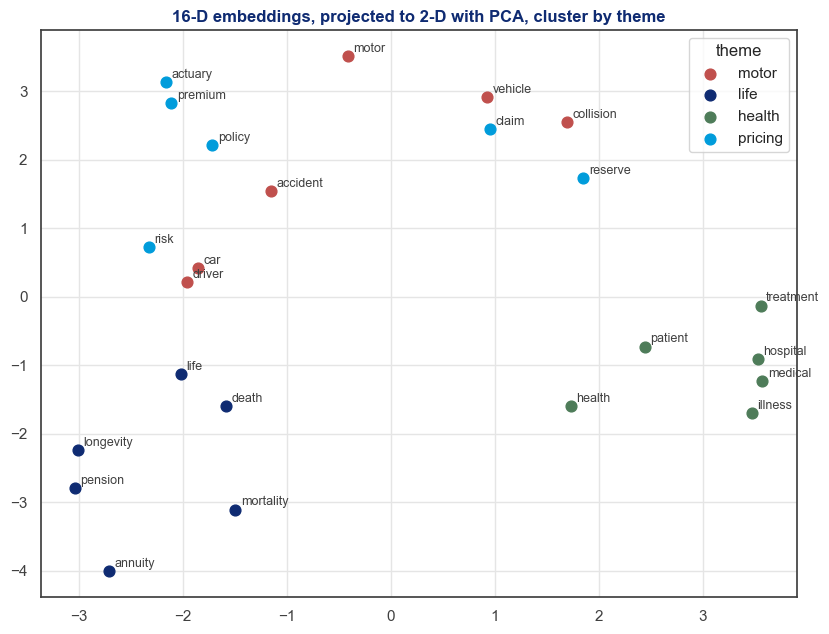

In [17]:
def pca_2d(M):
    Mc = M - M.mean(axis=0)
    _, _, Vt = np.linalg.svd(Mc, full_matrices=False)
    return Mc @ Vt[:2].T            # project onto the top-2 principal directions

themes = {
    "motor":   (ACCENT_RED,
                ["car", "driver", "accident", "motor", "vehicle", "collision"]),
    "life":    (PRIMARY,
                ["life", "mortality", "annuity", "death", "longevity", "pension"]),
    "health":  (ACCENT_GREEN,
                ["health", "medical", "hospital", "patient", "treatment", "illness"]),
    "pricing": (ACCENT_CYAN,
                ["premium", "risk", "actuary", "claim", "policy", "reserve"]),
}

def plot_embeddings(emb, title, ax=None):
    coords = pca_2d(emb)
    if ax is None:
        _, ax = plt.subplots(figsize=(8.5, 6.5))
    for theme, (col, words) in themes.items():
        pts = np.array([coords[word2id[w]] for w in words])
        ax.scatter(pts[:, 0], pts[:, 1], color=col, s=60, label=theme, zorder=3)
        for w, (x, y) in zip(words, pts):
            ax.annotate(w, (x, y), fontsize=9, xytext=(4, 3),
                        textcoords="offset points", color=GRAY_TEXT)
    ax.set_title(title)
    ax.legend(title="theme", loc="best")
    return ax

plot_embeddings(emb, "16-D embeddings, projected to 2-D with PCA, cluster by theme")
plt.tight_layout()
plt.show()

### 2.5 Interactive: the context window

The **context window** $k$ sets how far the “company a word keeps” reaches. A narrow window (1) captures tight, almost grammatical neighbours; a wider window blends in broader topical context. Drag the sliders and watch the clusters reorganise (each change re-trains the model from scratch, so allow a second or two).

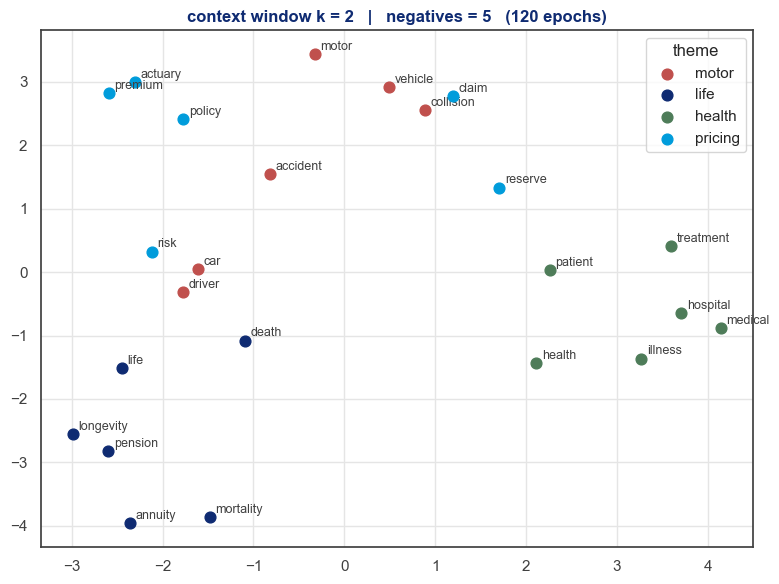

interactive(children=(IntSlider(value=2, description='window k', max=5, min=1), IntSlider(value=5, description…

In [18]:
def w2v_window_demo(window=2, negatives=5):
    e = fit_word2vec(window=int(window), n_neg=int(negatives), dim=16, epochs=120)
    fig, ax = plt.subplots(figsize=(8, 6))
    plot_embeddings(e, f"context window k = {window}   |   negatives = {negatives}"
                       "   (120 epochs)", ax=ax)
    fig.tight_layout()
    plt.show()

w2v_window_demo(2, 5)
interact(
    w2v_window_demo,
    window=IntSlider(value=2, min=1, max=5, step=1, description="window k"),
    negatives=IntSlider(value=5, min=1, max=15, step=1, description="negatives"),
);

### Exercise 2

1. **Probe a word.** Print the five nearest neighbours of `"actuary"` and of `"claim"`. The bridge words (used across themes) should sit between the clusters.
2. **Window width.** Re-train with `window=1` and `window=5` and compare the neighbours of `"mortality"`.
3. *(Optional)* **Extend the corpus.** Add two or three sentences about a new theme (e.g. **cyber** risk) and re-run Section 2 from the top. Does the new vocabulary form its own cluster?

<details>
<summary><b>Show solution</b></summary>

```python
# (1) Nearest neighbours of two bridge words
for w in ["actuary", "claim"]:
    print(f"{w:9s} -> {nearest(w, emb)}")

# (2) Effect of the context window on the 'mortality' neighbourhood
for win in [1, 5]:
    e = fit_word2vec(window=win, dim=16, epochs=300)
    print(f"window={win}: mortality -> {nearest('mortality', e)}")
# A narrow window keys on immediate companions; a wide one mixes in the whole
# sentence's topic. Both keep life-theme words close (k = 1: longevity; k = 5: life).

# (3) Extend the corpus, then re-execute Section 2.1 onward
extra = [
    "the cyber policy covers a data breach and ransomware",
    "a data breach raises the cyber insurance premium",
    "the insurer modelled cyber risk and the breach claim",
]
# corpus = corpus + extra   # uncomment, then re-run cells 2.1 -> 2.4
```

</details>

## 3. The language-modelling head: turning scores into the next token <a id="lmhead"></a>

A generative language model works one token at a time. After all its internal machinery (the transformer blocks), it produces a vector $h$ summarising “everything so far”. The **language-modelling head** (building block (IV) on the slides) turns that vector into a **probability distribution over the next token**, and then a **sampling** step (building block (V)) picks one. This section builds both – and they are the very knobs you will turn on GPT-2 in Section 4.

**From a vector to scores.** The head multiplies $h$ by the (transposed) embedding matrix $E$ to get one **score** (logit) per vocabulary token:

$$u = h\,E^\top \in \mathbb{R}^{|V|}.$$

**From scores to probabilities.** A **softmax with temperature** $T>0$ turns the scores into probabilities:

$$p_i = \frac{\exp(u_i / T)}{\sum_{j} \exp(u_j / T)}.$$

Temperature is the master dial: $T<1$ **sharpens** the distribution (more deterministic), $T>1$ **flattens** it (more random).

### 3.1 The softmax with temperature

Let us implement the formula and check it on the three-token example of the slide *(IV) Language modelling head: Temperature*, with scores $u=(-0.3,\ 0.4,\ 0.7)$.

In [19]:
def softmax_with_temperature(logits, T=1.0):
    logits = np.asarray(logits, dtype=float)
    z = logits / T
    z = z - z.max()              # numerical stability only (no effect on the result)
    e = np.exp(z)
    return e / e.sum()

u = np.array([-0.3, 0.4, 0.7])
for T in (0.4, 1.0, 2.0):
    print(f"T = {T}:  p = {np.round(softmax_with_temperature(u, T), 2)}")

# A small, readable 'next-token' distribution for an imagined actuarial prompt
# such as: "The actuary calculated the ..."
TOKENS = ["claim", "premium", "policy", "risk", "reserve",
          "mortality", "fraud", "loss", "actuary", "the"]
LOGITS = np.array([2.6, 2.3, 1.9, 1.6, 1.2, 0.9, 0.5, 0.2, -0.2, -0.6])
print("\nbase probabilities (T = 1):")
p_base = softmax_with_temperature(LOGITS, 1.0)
print({t: round(float(p), 2) for t, p in zip(TOKENS, p_base)})

T = 0.4:  p = [0.05 0.3  0.64]
T = 1.0:  p = [0.17 0.35 0.47]
T = 2.0:  p = [0.25 0.35 0.41]

base probabilities (T = 1):
{'claim': 0.3, 'premium': 0.22, 'policy': 0.15, 'risk': 0.11, 'reserve': 0.07, 'mortality': 0.05, 'fraud': 0.04, 'loss': 0.03, 'actuary': 0.02, 'the': 0.01}


At $T=0.4$ the distribution concentrates on the top token (0.64); at $T=2$ it spreads out (0.25 / 0.35 / 0.41). These are the values on the slide, where some are rounded to one decimal. The relative *ordering* never changes – temperature only redistributes the mass.

### 3.2 Temperature in pictures

The same ten scores, viewed at three temperatures:

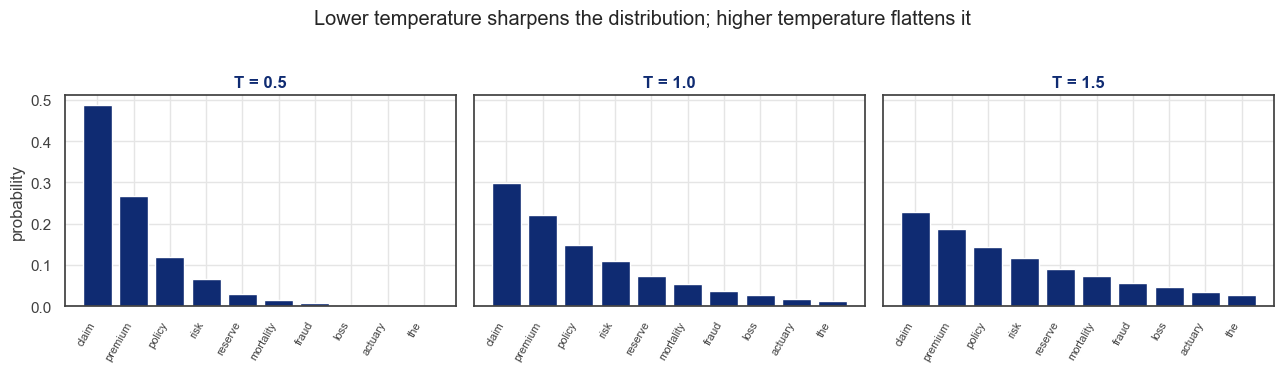

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 1.5]):
    p = softmax_with_temperature(LOGITS, T)
    ax.bar(range(len(TOKENS)), p, color=PRIMARY)
    ax.set_xticks(range(len(TOKENS)))
    ax.set_xticklabels(TOKENS, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"T = {T}")
axes[0].set_ylabel("probability")
fig.suptitle("Lower temperature sharpens the distribution; "
             "higher temperature flattens it", y=1.03)
fig.tight_layout()
plt.show()

### 3.3 Decoding strategies: greedy, top-k, top-p

Once we have the distribution, how do we choose? The three strategies of the slide *(V) Sampling*:

- **Greedy sampling** – always take the single most probable token. Deterministic; *temperature-independent*.
- **Top-k sampling** – keep only the $k$ highest-probability tokens, renormalise, then sample.
- **Top-p (nucleus) sampling** – keep the smallest set of top tokens whose probabilities add up to at least $p$, renormalise, then sample.

Top-k and top-p both **discard the unreliable tail** before sampling – they can only ever *remove* tokens (and renormalise the rest), never change the order of the survivors. We implement all of them from scratch.

In [21]:
def top_k_filter(probs, k):
    if not k or k >= len(probs):
        return probs.copy()
    keep = np.argsort(-probs)[:k]
    out = np.zeros_like(probs)
    out[keep] = probs[keep]
    return out / out.sum()

def top_p_filter(probs, p):
    if p >= 1.0:
        return probs.copy()
    order = np.argsort(-probs)
    cum = np.cumsum(probs[order])
    cutoff = int(np.searchsorted(cum, p)) + 1     # smallest nucleus reaching p
    keep = order[:cutoff]
    out = np.zeros_like(probs)
    out[keep] = probs[keep]
    return out / out.sum()

def choose_next(logits, T=1.0, top_k=0, top_p=1.0, mode="sample", rng=None):
    if mode == "greedy":
        return int(np.argmax(logits))           # the argmax, regardless of temperature
    probs = softmax_with_temperature(logits, T)
    if top_k:
        probs = top_k_filter(probs, top_k)
    if top_p < 1.0:
        probs = top_p_filter(probs, top_p)
    rng = rng or np.random.default_rng()
    return int(rng.choice(len(probs), p=probs))

probs = softmax_with_temperature(LOGITS, 1.0)
kept_k, kept_p = top_k_filter(probs, 3), top_p_filter(probs, 0.9)
print("top_k = 3   keeps:", [t for t, q in zip(TOKENS, kept_k) if q > 0])
print("top_p = 0.9 keeps:", [t for t, q in zip(TOKENS, kept_p) if q > 0])

top_k = 3   keeps: ['claim', 'premium', 'policy']
top_p = 0.9 keeps: ['claim', 'premium', 'policy', 'risk', 'reserve', 'mortality']


### 3.4 Interactive: the decoding hub

This is the heart of the section. Drag the sliders to reshape the distribution and see which token gets chosen. **Green** bars are *eligible* tokens (they survived the filters); the **red** bar is the token actually selected. Switch `mode` to *greedy* to see it ignore every knob and always grab the tallest bar.

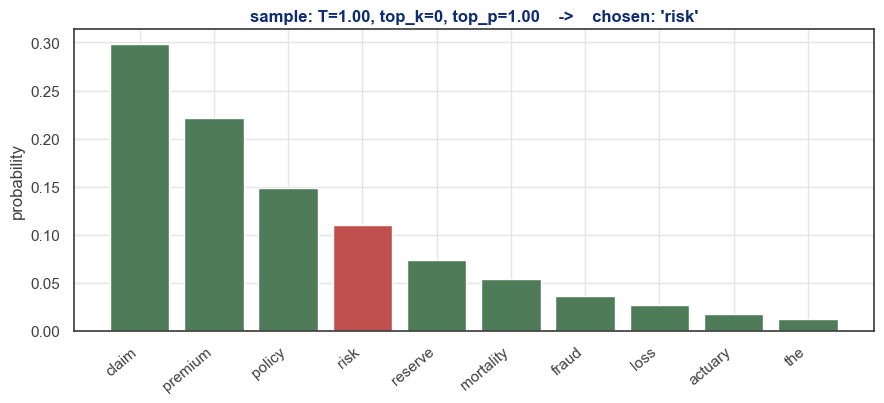

interactive(children=(FloatSlider(value=1.0, description='temperature', max=2.5, min=0.1, step=0.05), IntSlide…

In [22]:
def decode_demo(temperature=1.0, top_k=0, top_p=1.0, mode="sample"):
    base = softmax_with_temperature(LOGITS, temperature)
    if mode == "greedy":
        shown = base
        chosen = int(np.argmax(LOGITS))
        eligible = np.zeros(len(TOKENS), dtype=bool)
        eligible[chosen] = True
    else:
        p = base.copy()
        if top_k:
            p = top_k_filter(p, top_k)
        if top_p < 1.0:
            p = top_p_filter(p, top_p)
        shown = p
        eligible = p > 0
        chosen = int(np.random.default_rng(SEED).choice(len(p), p=p))

    colors = [ACCENT_GREEN if eligible[i] else "#d9d9d9" for i in range(len(TOKENS))]
    colors[chosen] = ACCENT_RED
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.bar(range(len(TOKENS)), shown, color=colors)
    ax.set_xticks(range(len(TOKENS)))
    ax.set_xticklabels(TOKENS, rotation=40, ha="right")
    ax.set_ylabel("probability")
    head = ("greedy: always the argmax (ignores T, top-k, top-p)" if mode == "greedy"
            else f"sample: T={temperature:.2f}, top_k={top_k}, top_p={top_p:.2f}")
    ax.set_title(f"{head}    ->    chosen: '{TOKENS[chosen]}'")
    fig.tight_layout()
    plt.show()

decode_demo(1.0, 0, 1.0, "sample")
interact(
    decode_demo,
    temperature=FloatSlider(value=1.0, min=0.1, max=2.5, step=0.05,
                            description="temperature"),
    top_k=IntSlider(value=0, min=0, max=10, step=1, description="top_k"),
    top_p=FloatSlider(value=1.0, min=0.1, max=1.0, step=0.05, description="top_p"),
    mode=Dropdown(options=["sample", "greedy"], value="sample", description="mode"),
);

### Exercise 3 – make the underdog win

The token `"fraud"` has a low base probability. Using only the controls above:

1. What temperature makes `"fraud"` a realistic possibility (say, probability above 0.08)?
2. Can **greedy** decoding ever output `"fraud"`? Why or why not?
3. Can raising **top-k** or **top-p** ever *increase* the probability of `"fraud"`?

Predict your answers first, then check.

<details>
<summary><b>Show solution</b></summary>

```python
fr = TOKENS.index("fraud")
for T in [1.0, 2.0, 3.0, 3.5, 5.0, 20.0]:
    p = softmax_with_temperature(LOGITS, T)
    print(f"T={T:5.1f}: P(fraud) = {p[fr]:.3f}, argmax = '{TOKENS[int(np.argmax(p))]}'")

p1 = softmax_with_temperature(LOGITS, 1.0)
for k in [6, 7, 10]:
    print(f"top_k = {k:2d}: P(fraud) = {top_k_filter(p1, k)[fr]:.3f}")
print("greedy always picks:", TOKENS[choose_next(LOGITS, mode="greedy")])

# (1) Temperature flattens the distribution towards uniform (1/10 = 0.10), so a
#     high T lifts P(fraud) above 0.08: from about T = 3.15 on (T = 3 gives
#     0.079, T = 3.5 gives 0.082).
# (2) NO. Greedy returns argmax(LOGITS) = 'claim' for ANY temperature -- the
#     ordering never changes, so the top token always wins.
# (3) Only by letting it back in: if a smaller top-k / top-p had cut 'fraud' off,
#     raising k or p re-admits it (top_k 6 -> 7: 0 -> 0.039; renormalisation even
#     puts it slightly above its unfiltered 0.037). But the filters never change
#     the order: 'fraud' can never overtake a token with a higher score.
```

The lesson that carries straight into GPT-2: **temperature** controls how adventurous the model is, while **top-k / top-p** prune the unreliable tail – but none of them changes the order: a token that the scores rank low never overtakes a higher-ranked one, and greedy decoding never picks it.

</details>

## 4. GPT-2: a real generative model, end to end <a id="gpt2"></a>

Time to put it together. **GPT** stands for **G**enerative **P**re-trained **T**ransformer (slide *GPT*):

- **Generative / autoregressive** – it predicts the next token, appends it, and repeats. The text it has produced so far becomes part of its own input.
- **Pre-trained** – it learned from a vast amount of internet text by doing exactly one thing billions of times: *predict the next token*.
- **Transformer** – its internal architecture is a *decoder-only* transformer with *masked self-attention*, so each token attends only to the tokens before it.

Crucially, GPT-2’s final step is the **language-modelling head from Section 3**, and we will drive it with the **exact same `choose_next` function** you wrote. The embeddings of Section 2 and the neural-network machinery of Section 1 are inside it too. **GPT-2 medium** has about 355 million parameters across 24 transformer blocks – small by today’s standards, but a genuine article.

GPT-2 is an **open-weights** model (slide *Closed weights, open weights and open source*): its weights can be downloaded, so it runs wherever this notebook runs – on your laptop or on the Colab machine – without sending prompts to a model provider and without an API key.

> **Language.** GPT-2 was trained almost exclusively on English web text. This section therefore uses English prompts; German or French prompts give poor results.

### 4.1 Load the model

The next cell downloads GPT-2 medium from the Hugging Face Hub: model [`openai-community/gpt2-medium`](https://huggingface.co/openai-community/gpt2-medium), the release named on the slide *Example: Number of parameters of GPT-2 (medium)*. **GPT-2 medium is about 1.5 GB and needs an internet connection the first time** (it is then cached). For a lighter, faster run, use the smaller `"openai-community/gpt2"` (about 124 million parameters, about 500 MB) – enter it in the cell, or set the environment variable `FIT4AI_MODEL_NAME` before starting Jupyter. If the download is unavailable, the rest of the section skips itself gracefully.

In [23]:
import os

# Default: GPT-2 medium (about 355 million parameters, about 1.5 GB).
# Faster: "openai-community/gpt2" (about 124 million parameters, about 500 MB) -
# enter it here, or set the environment variable FIT4AI_MODEL_NAME before
# starting Jupyter.
MODEL_NAME = os.environ.get("FIT4AI_MODEL_NAME", "openai-community/gpt2-medium")

GPT2_OK = False
try:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    model.eval()                                   # inference mode (no dropout)

    cfg = model.config
    n_params = sum(p.numel() for p in model.parameters())
    sizes = {12: "GPT-2", 24: "GPT-2 medium", 36: "GPT-2 large", 48: "GPT-2 XL"}
    name = sizes.get(cfg.n_layer, MODEL_NAME)
    print(f"Loaded {name}: {n_params / 1e6:.0f} million parameters")
    print(f"  layers = {cfg.n_layer},  d_model = {cfg.n_embd},  heads h = {cfg.n_head},"
          f"  d_head = {cfg.n_embd // cfg.n_head},"
          f"  d_ff = {cfg.n_inner or 4 * cfg.n_embd}")
    print(f"  vocabulary = {cfg.vocab_size:,} tokens,"
          f"  maximum context = {cfg.n_positions:,} tokens")
    GPT2_OK = True
except Exception as e:
    print("Could not load GPT-2 (no internet connection,"
          " or torch/transformers unavailable).")
    print("Reason:", repr(e)[:200])
    print("Sections 4.2-4.5 will skip themselves;"
          " everything above this point still runs.")

Loaded GPT-2 medium: 355 million parameters
  layers = 24,  d_model = 1024,  heads h = 16,  d_head = 64,  d_ff = 4096
  vocabulary = 50,257 tokens,  maximum context = 1,024 tokens


### 4.2 Where are the 355 million parameters?

The next cell counts GPT-2’s parameters by building block, for comparison with the slide *Example: Number of parameters of GPT-2 (medium)* (embedding approx. 51.5 million, layer norm approx. 100,000, masked multi-head attention approx. 100.7 million, feed-forward layer approx. 201.3 million, total approx. 354 million). It lists the weight **matrices** separately from the small bias and gain **vectors**. The language-modelling head has no parameters of its own: GPT-2 reuses the embedding matrix $E$ for the “unembedding” $u = h_N E^\top$ (slide *(IV) Language modelling head*).

In [24]:
if GPT2_OK:
    blocks = ["Token embedding (wte)", "Position embedding (wpe)", "Layer norm",
              "Masked multi-head attention", "Feed-forward layer", "Other"]
    matrices = dict.fromkeys(blocks, 0)
    vectors = dict.fromkeys(blocks, 0)            # bias and gain vectors
    # The tied LM-head matrix is listed only once, as wte.
    for pname, prm in model.named_parameters():
        if ".wte." in pname:
            block = "Token embedding (wte)"
        elif ".wpe." in pname:
            block = "Position embedding (wpe)"
        elif ".ln_" in pname:
            block = "Layer norm"
        elif ".attn." in pname:
            block = "Masked multi-head attention"
        elif ".mlp." in pname:
            block = "Feed-forward layer"
        else:
            block = "Other"
        (matrices if prm.dim() == 2 else vectors)[block] += prm.numel()

    def row(label, m, v):                         # one table row, in millions
        print(f"{label:29s}{m / 1e6:10.2f}{v / 1e6:10.2f}{(m + v) / 1e6:10.2f}")

    print(f"{'building block':29s}{'matrices':>10s}{'vectors':>10s}{'total':>10s}"
          "   (millions)")
    for b in blocks:
        if b == "Other" and matrices[b] + vectors[b] == 0:
            continue
        row(b, matrices[b], vectors[b])
    row("Total", sum(matrices.values()), sum(vectors.values()))

    slide_basis = (matrices["Token embedding (wte)"] + vectors["Layer norm"]
                   + matrices["Masked multi-head attention"]
                   + matrices["Feed-forward layer"])
    print("\nAs on the slide (no wpe, no attention/feed-forward biases): "
          f"{slide_basis / 1e6:.2f} million")
    tied = (model.get_output_embeddings().weight.data_ptr()
            == model.get_input_embeddings().weight.data_ptr())
    print("LM head shares its weight matrix with wte:", tied)
else:
    print("[skipped - GPT-2 not loaded]")

building block                 matrices   vectors     total   (millions)
Token embedding (wte)             51.46      0.00     51.46
Position embedding (wpe)           1.05      0.00      1.05
Layer norm                         0.00      0.10      0.10
Masked multi-head attention      100.66      0.10    100.76
Feed-forward layer               201.33      0.12    201.45
Total                            354.50      0.32    354.82

As on the slide (no wpe, no attention/feed-forward biases): 353.55 million
LM head shares its weight matrix with wte: True


The table reproduces the slide: the token embedding has 51.46 million parameters (approx. 51.5 million), the 49 layer norms (two per block plus a final one) have 0.10 million (approx. 100,000), and the weight matrices of attention and feed-forward layers have 100.66 and 201.33 million (approx. 100.7 and 201.3 million). Together these make the 353.55 million printed above – the slide’s total of approx. 354 million. The slide leaves out the small bias vectors of attention and feed-forward layers (0.10 and 0.12 million). Two further remarks:

- GPT-2 does not add a fixed positional encoding; it **learns** its position embeddings (wpe: 1,024 positions × 1,024 dimensions ≈ 1.05 million parameters), which the slide does not count. With wpe and the bias vectors the total is 354.82 million – the “approx. 355 million” on the slide *Comparison of GPT-2 & GPT-4*.
- The language-modelling head reuses wte, so the unembedding costs no extra parameters, as stated on the slide.

### 4.3 Tokenisation: how GPT-2 splits text

GPT-2 uses **byte-pair encoding (BPE)** with a vocabulary of 50,257 tokens (slides *Bottom-up tokenisation* and *Example: byte-pair encoding (BPE)*). The vocabulary was learned mainly from English text. The cell tokenises single words – each with the leading space it has inside a sentence – and then one sentence in English, German and French.

In [25]:
if GPT2_OK:
    def pieces(text):
        return [tokenizer.decode([i]) for i in tokenizer.encode(text)]

    words = ["insurance", "premium", "mortality", "smaller", "cleaner",
             "actuary", "reinsurance", "unfitness", "injective", "surjective",
             "Versicherungsprämie", "Lebensversicherung", "Rückversicherung"]
    for w in words:
        toks = pieces(" " + w)                   # as the word appears inside a sentence
        unit = "tokens" if len(toks) > 1 else "token "
        print(f"{w:20s} {len(toks)} {unit}:  {' | '.join(t.strip() for t in toks)}")

    print()
    sentences_3 = {
        "English": "The actuary calculates the premium for the life insurance.",
        "German":  "Der Aktuar berechnet die Prämie für die Lebensversicherung.",
        "French":  "L'actuaire calcule la prime de l'assurance-vie.",
    }
    for lang, s in sentences_3.items():
        n_words, n_tok = len(s.split()), len(tokenizer.encode(s))
        print(f"{lang:8s} {n_words} words -> {n_tok:2d} tokens  "
              f"({n_tok / n_words:.2f} tokens per word)")
else:
    print("[skipped - GPT-2 not loaded]")

insurance            1 token :  insurance
premium              1 token :  premium
mortality            1 token :  mortality
smaller              1 token :  smaller
cleaner              1 token :  cleaner
actuary              2 tokens:  act | uary
reinsurance          2 tokens:  reins | urance
unfitness            2 tokens:  unf | itness
injective            2 tokens:  inject | ive
surjective           3 tokens:  sur | ject | ive
Versicherungsprämie  7 tokens:  Vers | ic | her | ung | spr | ä | mie
Lebensversicherung   7 tokens:  Le | b | ens | vers | ic | her | ung
Rückversicherung     7 tokens:  R | ü | ck | vers | ic | her | ung

English  9 words -> 11 tokens  (1.22 tokens per word)
German   8 words -> 22 tokens  (2.75 tokens per word)
French   6 words -> 18 tokens  (3.00 tokens per word)


Frequent English words such as *insurance*, *premium* and *mortality* are single tokens, while rarer words are split into subword tokens (*act | uary*, *reins | urance*). The pieces come from learned merge frequencies, not from grammar: *unfitness* becomes *unf | itness* rather than the morphemes *Un | fit | ness* of the slide *Words and corpora*, and *surjective* becomes *sur | ject | ive*, whereas the toy corpus on the slide *Example: byte-pair encoding (BPE)* merges its ending into *tive_* and *jective_* – which pieces arise depends on the training corpus. For the same reason GPT-2 keeps *smaller* and *cleaner* whole: both are frequent in English web text, so each became a token of its own. The split into *small*, *clean* and *er* on the slide *Bottom-up tokenisation* illustrates the principle with a much smaller vocabulary. German compounds fall apart into many short pieces – each of the three German words needs seven tokens – and the same sentence costs GPT-2 more than twice as many tokens per word in German or French as in English. Context windows and the cost of commercial language models are counted in tokens, so this matters in practice.

### 4.4 The autoregressive loop, exposed

Here is generation stripped to its essence – the loop on the slide *Application of the decoder-only transformer*. We tokenise the prompt, then repeatedly: run the model to get the **next-token scores**, hand them to **our own `choose_next`** (temperature + top-k + top-p, straight from Section 3), append the chosen token, and loop.

We start from the slide’s example after its first two generated words: “To calculate insurance premiums, the actuary uses”. First, a look at the language-modelling head of the real model: which next tokens does GPT-2 medium consider most probable? The slide’s continuation “mortality tables.” is an illustration; a small general-purpose model from 2019 ranks other tokens higher. Then watch the sentence grow one token at a time.

In [26]:
def gpt2_next_logits(input_ids):
    with torch.no_grad():
        out = model(input_ids)
    # scores for the next token over the whole vocabulary
    return out.logits[0, -1, :].float().numpy()

def gpt2_generate(prompt, max_new_tokens=30, T=0.8, top_k=50, top_p=0.95,
                  mode="sample", seed=SEED, show=True):
    ids = tokenizer.encode(prompt, return_tensors="pt")
    gen = np.random.default_rng(seed)
    if show:
        print(prompt, end="")
    for _ in range(max_new_tokens):
        logits = gpt2_next_logits(ids)
        nxt = choose_next(logits, T=T, top_k=top_k, top_p=top_p, mode=mode, rng=gen)
        if nxt == tokenizer.eos_token_id:
            break
        ids = torch.cat([ids, torch.tensor([[nxt]])], dim=1)
        if show:
            print(tokenizer.decode([nxt]), end="")
    if show:
        print()
    return tokenizer.decode(ids[0])

if GPT2_OK:
    prompt = "To calculate insurance premiums, the actuary uses"
    prompt_ids = tokenizer.encode(prompt, return_tensors="pt")
    p_next = softmax_with_temperature(gpt2_next_logits(prompt_ids), T=1.0)
    print(f"Prompt: {prompt!r}")
    print("The five most probable next tokens (T = 1):")
    for i in np.argsort(-p_next)[:5]:
        print(f"   {tokenizer.decode([int(i)])!r:16s} p = {p_next[i]:.3f}")
    m_id = tokenizer.encode(" mortality")[0]
    print(f"   ' mortality' (the slide's next word): p = {p_next[m_id]:.4f}, "
          f"rank {int((p_next > p_next[m_id]).sum()) + 1:,} of {len(p_next):,}")

    print("\nSampled continuation (T = 0.8, top_k = 50, top_p = 0.95):")
    _ = gpt2_generate(prompt, max_new_tokens=30, T=0.8)
else:
    print("[skipped - GPT-2 not loaded]")

Prompt: 'To calculate insurance premiums, the actuary uses'
The five most probable next tokens (T = 1):
   ' the'           p = 0.228
   ' a'             p = 0.156
   ' data'          p = 0.050
   ' an'            p = 0.040
   ' information'   p = 0.034
   ' mortality' (the slide's next word): p = 0.0008, rank 110 of 50,257

Sampled continuation (T = 0.8, top_k = 50, top_p = 0.95):
To calculate insurance premiums, the actuary uses all of the following: the income for the year, the average premium for the year, and the average age at which people were insured.




### 4.5 Greedy vs. sampling, and the parameter knobs

In practice you would call the library’s optimised `model.generate(...)`, which exposes the very same controls. Compare **greedy** (deterministic, can be repetitive) with **sampling** (varied, occasionally surprising) on one prompt.

In [27]:
if GPT2_OK:
    prompt = "An actuary's main task is to"
    enc = tokenizer(prompt, return_tensors="pt")

    torch.manual_seed(SEED)
    greedy = model.generate(**enc, max_new_tokens=40, do_sample=False,
                            pad_token_id=tokenizer.eos_token_id)

    torch.manual_seed(SEED)
    sampled = model.generate(**enc, max_new_tokens=40, do_sample=True,
                             temperature=0.9, top_k=50, top_p=0.95,
                             pad_token_id=tokenizer.eos_token_id)

    print("GREEDY (do_sample=False):\n",
          tokenizer.decode(greedy[0], skip_special_tokens=True))
    print("\nSAMPLED (T=0.9, top_k=50, top_p=0.95):\n",
          tokenizer.decode(sampled[0], skip_special_tokens=True))
else:
    print("[skipped - GPT-2 not loaded]")

GREEDY (do_sample=False):
 An actuary's main task is to estimate the value of a stock's future earnings. The value of a stock's future earnings is the sum of the future earnings of the company and the present value of future earnings of the company. The

SAMPLED (T=0.9, top_k=50, top_p=0.95):
 An actuary's main task is to determine which functions a function can perform. A function can perform any function that a method would do, but an actuator is only allowed to perform functions that cannot be duplicated by a method or a


Temperature controls how adventurous the text is – exactly as in Section 3, now on a vocabulary of 50,257 tokens. Low temperature makes the text more stable and less varied; high temperature makes it more diverse (and risks nonsense). For **actuarial use**, where accuracy, reliable sources and validation matter most, a low temperature is generally preferable (slides *(V) Sampling*) – but it prevents neither hallucinations nor outdated or biased statements.

In [28]:
if GPT2_OK:
    for T in [0.3, 1.3]:
        print(f"--- temperature = {T} ---")
        gpt2_generate("Insurance is", max_new_tokens=30, T=T, top_k=50, top_p=0.95,
                      seed=SEED)
        print()
else:
    print("[skipped - GPT-2 not loaded]")

--- temperature = 0.3 ---
Insurance is a big part of the equation. It's the number one reason why people get sick. It's also the reason why people get sick.



--- temperature = 1.3 ---
Insurance is often used by businesses to insure workers against any financial loss resulting from illness and injury.

Exercise of Employee Benefits – This area of the economy



Note the low-temperature run: it is stable, but it loops and is still wrong – a low temperature reduces variability, not errors (slide *(V) Sampling*: it prevents neither hallucinations nor outdated or biased statements). The high-temperature run happens to read well here; try a few other values for `seed` to see how much it varies.

### Exercise 4

1. **Style and length.** Pick a prompt (e.g. `"The Solvency Capital Requirement is"`). Generate a *focused* version (low temperature, short) and an *exploratory* version (high temperature, longer). Which would you trust in a first draft, and which for brainstorming?
2. **Greedy vs. sampled.** Generate the same prompt with `mode="greedy"` and `mode="sample"` and describe the difference in feel.

<details>
<summary><b>Show solution</b></summary>

```python
if GPT2_OK:
    p = "The Solvency Capital Requirement is"

    print("FOCUSED (T=0.3, 25 tokens):")
    gpt2_generate(p, max_new_tokens=25, T=0.3, top_k=50, top_p=0.9, seed=1)

    print("\nEXPLORATORY (T=1.1, 60 tokens):")
    gpt2_generate(p, max_new_tokens=60, T=1.1, top_k=100, top_p=0.98, seed=1)

    print("\nGREEDY:")
    gpt2_generate(p, max_new_tokens=30, mode="greedy")
    print("\nSAMPLED:")
    gpt2_generate(p, max_new_tokens=30, mode="sample", T=0.9, seed=7)
# Low temperature -> coherent and consistent (good for a first draft you will edit).
# High temperature -> diverse and idea-rich, but more likely to wander or invent.
# Greedy is deterministic and can loop; sampling feels more natural but varies
# from run to run.
```

</details>

## 5. Summary and further reading <a id="summary"></a>

You have built the whole pipeline of modern generative AI from the ground up:

| Section | What you built | The idea it teaches |
|---|---|---|
| **1. Neural networks** | the 2-3-1 network of the slides, trained by hand with full forward pass and backpropagation – with the slides’ numbers | networks *learn* by gradient descent on a loss |
| **2. Embeddings (word2vec)** | skip-gram with negative sampling, visualised in 2-D | meaning becomes *geometry* – similar words sit close |
| **3. LM head + decoding** | softmax with temperature, top-k, top-p, greedy | scores become a distribution; *how you sample* shapes the output |
| **4. GPT-2** | a real 355-million-parameter model: its parameters, its tokeniser and its generation loop | a transformer is these pieces, scaled up and stacked deep |

The thread running through all four: a generative model is **a next-token predictor**, trained by **gradient descent**, that represents language as **vectors**, and **samples** its way forward one token at a time. GPT-2 is not different in kind from the tiny network in Section 1 – only in scale.

### Keeping expectations realistic

Understanding the mechanics also clarifies the **limits** (slides *Limitations of GenAI* and *Challenges in dealing with GenAI*), which matter for any actuarial use:

- **No notion of truth.** The model optimises *plausibility*, not correctness. Confident-sounding but wrong output (“hallucination”) is a consequence of how it is trained, not a bug that can be fully patched.
- **It inherits its data.** Biases, gaps and stale facts in the training text flow straight into the output.
- **Finite context and knowledge cut-off.** It only “sees” a bounded window of tokens (GPT-2: 1,024 tokens; today’s large language models: 1 million tokens and more) and knows nothing after its training date.
- **Sampling means variability.** With `do_sample=True`, the same prompt can give different answers – reproducibility needs a fixed seed or greedy decoding.

For actuaries this suggests where today’s GenAI earns its keep – **drafting, summarising, extracting structure from documents, writing and explaining code** – always with a human reviewing the output, and always mindful of confidentiality, bias and auditability.

### Further reading

- Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft, free online: [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3)) – the book recommendation on the slide *Literature*: language models, embeddings and transformers, rigorous yet readable.
- Mikolov et al. (2013), *Efficient Estimation of Word Representations in Vector Space* – the original skip-gram (word2vec) paper.
- Mikolov et al. (2013), *Distributed Representations of Words and Phrases and their Compositionality* – negative sampling and the unigram$^{0.75}$ noise distribution used in Section 2.2.
- Vaswani et al. (2017), *Attention Is All You Need* – the transformer architecture behind Section 4.
- Radford et al. (2019), *Language Models are Unsupervised Multitask Learners* – the GPT-2 paper.
- Goodfellow, Bengio & Courville, *Deep Learning* (MIT Press, free online) – neural-network foundations for Section 1.
- 3Blue1Brown, *Neural networks* video series – outstanding visual intuition for Sections 1, 3 and 4.
- The Hugging Face [`transformers`](https://huggingface.co/docs/transformers) documentation and free courses – for going further than GPT-2.

---

*Fit4AI compact – Module 7: Generative Artificial Intelligence, companion notebook. EAA Inhouse Seminar SAV | Zurich, 19/20 November 2026. Code released under the MIT License; see the repository’s `LICENSE`. Built for the European Actuarial Academy.*